# Klasyfikacja sentymentu wiadomości tekstowej — Etap 1

**Projekt – Sieci Neuronowe** · Karol Salamon (280091), Maciej Soroka (284196)

Cel etapu 1: przygotować dane i uzyskać pierwszy wynik z prostej sieci neuronowej.

1. Wczytanie zbioru *IMDB Dataset of 50K Movie Reviews* (Kaggle)
2. Analiza danych (EDA)
3. Czyszczenie tekstu
4. Podział na zbiór uczący / walidacyjny / testowy
5. Zamiana tekstu na liczby (słownik, kodowanie, dopełnianie)
6. Punkt odniesienia bez sieci: TF-IDF + regresja logistyczna
7. Sieć neuronowa — model bazowy
8. Szybki test na własnych zdaniach

In [1]:
import sys
import textwrap
from collections import Counter
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, classification_report, confusion_matrix

from src.data import load_imdb, make_loader, remove_duplicates, split_data
from src.download_data import download
from src.model import MeanEmbeddingClassifier, count_parameters
from src.predict import describe, predict_texts
from src.preprocessing import STOPWORDS, Vocab, clean_text, encode_texts, tokenize
from src.train import fit, get_device, predict_proba, save_checkpoint, set_seed

SEED = 42
set_seed(SEED)

COLORS = {"negative": "#c0392b", "positive": "#27ae60"}
LABEL_PL = {"negative": "negatywne", "positive": "pozytywne"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_colwidth", 120)

## 1. Wczytanie danych

Jeśli pliku nie ma w `data/`, zostanie pobrany z Kaggle.

In [2]:
csv_path = download()
df = load_imdb(csv_path)
print(f"Liczba recenzji: {len(df):,}, kolumny: {list(df.columns)}")
df.head()

Plik już istnieje: /Users/salak/Desktop/studia/S5/AI/data/IMDB Dataset.csv
Liczba recenzji: 50,000, kolumny: ['review', 'sentiment', 'label']


,review,sentiment,label
0,"One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as ...",positive,1
1,A wonderful little production. <br /><br />The filming technique is very unassuming- very old-time-BBC fashion and g...,positive,1
2,"I thought this was a wonderful way to spend time on a too hot summer weekend, sitting in the air conditioned theater...",positive,1
3,Basically there's a family where a little boy (Jake) thinks there's a zombie in his closet & his parents are fightin...,negative,0
4,"Petter Mattei's ""Love in the Time of Money"" is a visually stunning film to watch. Mr. Mattei offers us a vivid portr...",positive,1


## 2. Analiza danych (EDA)

### 2.1 Rozkład klas

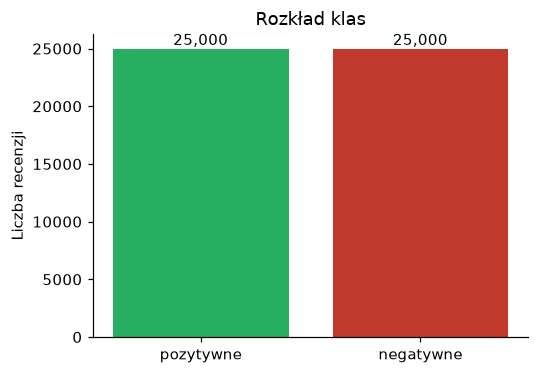

In [3]:
counts = df["sentiment"].value_counts()
fig, ax = plt.subplots(figsize=(5, 3.5))
bars = ax.bar([LABEL_PL[s] for s in counts.index], counts.values, color=[COLORS[s] for s in counts.index])
ax.bar_label(bars, labels=[f"{v:,}" for v in counts.values])
ax.set(title="Rozkład klas", ylabel="Liczba recenzji")
fig.tight_layout()
plt.show()

Zbiór jest idealnie zbalansowany (po 25 000 recenzji w każdej klasie), więc *accuracy* jest sensowną miarą,
a model, który zgaduje losowo, osiąga ok. 50%.

### 2.2 Duplikaty

In [4]:
n_dup = df["review"].duplicated().sum()
print(f"Powtórzone recenzje: {n_dup}")
df = remove_duplicates(df)
print(f"Po usunięciu duplikatów: {len(df):,} recenzji")
df["sentiment"].value_counts()

Powtórzone recenzje: 418
Po usunięciu duplikatów: 49,582 recenzji


sentiment
positive    24884
negative    24698
Name: count, dtype: int64

Duplikaty usuwamy **przed** podziałem danych — inaczej ta sama recenzja mogłaby trafić jednocześnie
do zbioru uczącego i testowego, co zawyżyłoby wynik.

### 2.3 Długość recenzji

,count,mean,std,min,25%,50%,75%,max
sentiment,,,,,,,,
negative,24698.0,229.6,165.1,4.0,128.0,174.0,278.0,1522.0
positive,24884.0,233.1,177.7,10.0,125.0,172.0,284.0,2470.0


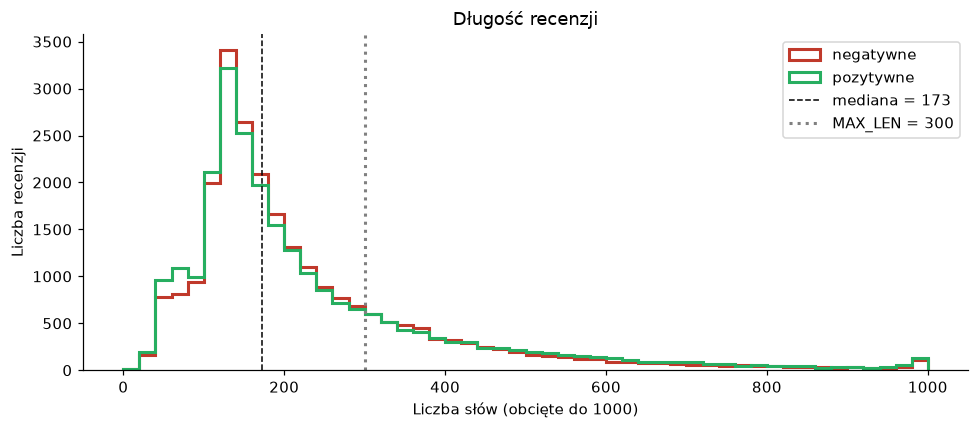

Recenzji o długości ≤ 300 słów: 77.7%


In [5]:
MAX_LEN = 300  # do tylu słów będziemy przycinać / dopełniać recenzje

df["n_words"] = df["review"].str.split().str.len()
display(df.groupby("sentiment")["n_words"].describe().round(1))

fig, ax = plt.subplots(figsize=(9, 4))
bins = np.arange(0, 1001, 20)
for s in ["negative", "positive"]:
    ax.hist(df.loc[df["sentiment"] == s, "n_words"].clip(upper=1000), bins=bins,
            histtype="step", linewidth=2, color=COLORS[s], label=LABEL_PL[s])
median = df["n_words"].median()
ax.axvline(median, color="black", ls="--", lw=1, label=f"mediana = {median:.0f}")
ax.axvline(MAX_LEN, color="gray", ls=":", lw=2, label=f"MAX_LEN = {MAX_LEN}")
ax.set(title="Długość recenzji", xlabel="Liczba słów (obcięte do 1000)", ylabel="Liczba recenzji")
ax.legend()
fig.tight_layout()
plt.show()

print(f"Recenzji o długości ≤ {MAX_LEN} słów: {(df['n_words'] <= MAX_LEN).mean():.1%}")

Długość recenzji jest podobna w obu klasach, więc sama długość nie zdradza sentymentu.
Rozkład ma długi ogon (najdłuższe recenzje mają ponad 2000 słów), dlatego ustalamy **MAX_LEN = 300** —
ok. 78% recenzji mieści się w całości, a dłuższe przycinamy.

### 2.4 Przykładowe recenzje

In [6]:
short = df[df["n_words"] < 70]
for s in ["positive", "negative"]:
    row = short[short["sentiment"] == s].sample(1, random_state=SEED).iloc[0]
    print(f"[{LABEL_PL[s].upper()}]")
    print(textwrap.fill(row["review"], 110), "\n")

[POZYTYWNE]
Andrew McCarthy played the role of an atheist very well. I liked the plot of the movie. It gave something to
think about other than a comedy. It had a very twisted mind and a good cop versus God. A very well used plot
line. 

[NEGATYWNE]
Michael Dudikoff stars as Joe Armstrong a martial artist who fights ninjas who are stealing weapons from the
U.S Army, in this entertaining yet admittedly brainless martial arts actioner, which is hampered by too many
long pauses without action, but helped by some high energy action setpieces as well as Steve James'
performance. 



## 3. Czyszczenie tekstu

Funkcja `clean_text` (plik `src/preprocessing.py`):
- zamienia litery na małe,
- usuwa znaczniki HTML (w tym zbiorze ok. 58% recenzji zawiera `<br />`) i adresy URL,
- usuwa interpunkcję i akcenty, zostawia litery, cyfry i apostrofy wewnątrz słów (`don't`, `isn't`),
- usuwa nadmiarowe spacje.

**Nie usuwamy negacji** (`not`, `no`, `never`, `don't`, ...), choć standardowe listy *stopwords* je zawierają —
„not good” znaczy coś przeciwnego niż „good”.

In [7]:
example = df[df["review"].str.contains("<br") & (df["n_words"] < 120)].iloc[0]["review"]
print("PRZED:\n" + textwrap.fill(example, 110))
print("\nPO:\n" + textwrap.fill(clean_text(example), 110))

PRZED:
If you like original gut wrenching laughter you will like this movie. If you are young or old then you will
love this movie, hell even my mom liked it.<br /><br />Great Camp!!!

PO:
if you like original gut wrenching laughter you will like this movie if you are young or old then you will
love this movie hell even my mom liked it great camp


In [8]:
df["clean"] = df["review"].map(clean_text)
df["tokens"] = df["clean"].map(tokenize)
df[["review", "clean"]].head(3)

,review,clean
0,"One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as ...",one of the other reviewers has mentioned that after watching just 1 oz episode you'll be hooked they are right as th...
1,A wonderful little production. <br /><br />The filming technique is very unassuming- very old-time-BBC fashion and g...,a wonderful little production the filming technique is very unassuming very old time bbc fashion and gives a comfort...
2,"I thought this was a wonderful way to spend time on a too hot summer weekend, sitting in the air conditioned theater...",i thought this was a wonderful way to spend time on a too hot summer weekend sitting in the air conditioned theater ...


### 3.1 Najczęstsze słowa w każdej klasie

Bez *stopwords* („the”, „and”, „is”, ...), ale z zachowaniem negacji.

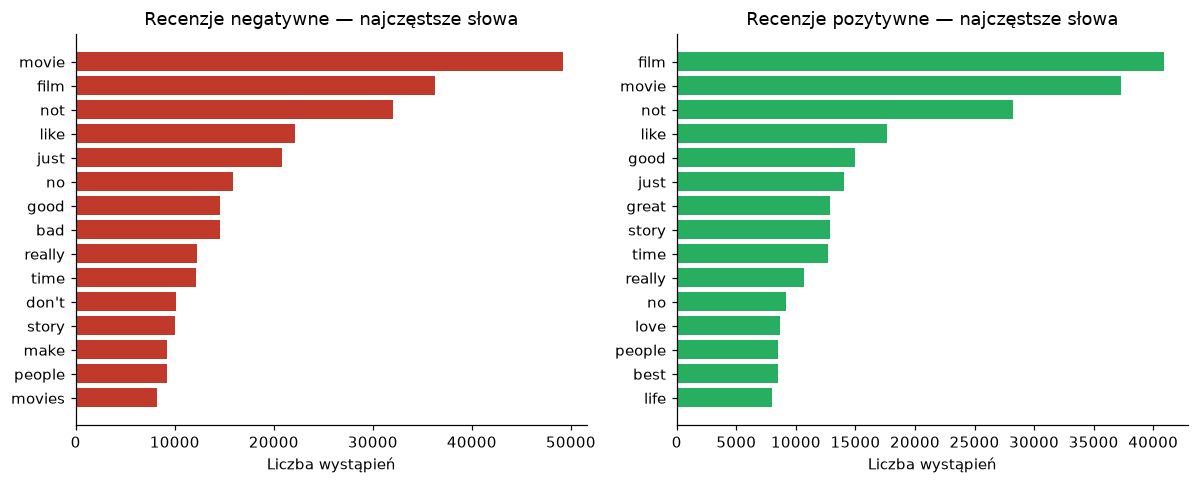

In [9]:
def word_counts(token_lists) -> Counter:
    c = Counter()
    for tokens in token_lists:
        c.update(t for t in tokens if t not in STOPWORDS)
    return c

counts = {s: word_counts(df.loc[df["sentiment"] == s, "tokens"]) for s in ["negative", "positive"]}

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, s in zip(axes, ["negative", "positive"]):
    words, freqs = zip(*counts[s].most_common(15))
    ax.barh(words[::-1], freqs[::-1], color=COLORS[s])
    ax.set_title(f"Recenzje {LABEL_PL[s]} — najczęstsze słowa")
    ax.set_xlabel("Liczba wystąpień")
fig.tight_layout()
plt.show()

Najczęstsze słowa w obu klasach są niemal takie same („movie”, „film”, „like”), więc same częstości
słabo rozróżniają sentyment. Ciekawsze jest, **które słowa są wyraźnie częstsze w jednej z klas**:

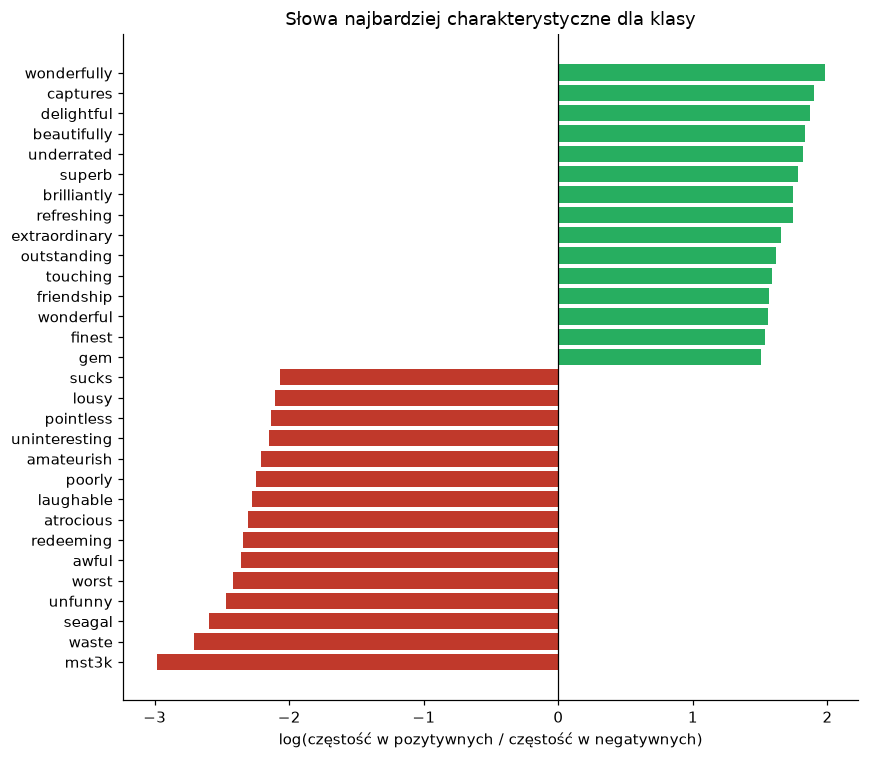

In [10]:
neg, pos = counts["negative"], counts["positive"]
total_neg, total_pos = sum(neg.values()), sum(pos.values())
rows = []
for w in set(neg) | set(pos):
    if neg[w] + pos[w] >= 300:  # pomijamy rzadkie słowa
        log_ratio = np.log(((pos[w] + 1) / total_pos) / ((neg[w] + 1) / total_neg))
        rows.append((w, log_ratio))
ratios = pd.DataFrame(rows, columns=["word", "log_ratio"]).sort_values("log_ratio")
sel = pd.concat([ratios.head(15), ratios.tail(15)])

fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(sel["word"], sel["log_ratio"],
        color=[COLORS["positive"] if r > 0 else COLORS["negative"] for r in sel["log_ratio"]])
ax.axvline(0, color="black", lw=0.8)
ax.set(title="Słowa najbardziej charakterystyczne dla klasy",
       xlabel="log(częstość w pozytywnych / częstość w negatywnych)")
fig.tight_layout()
plt.show()

## 4. Podział danych

80% uczący / 10% walidacyjny / 10% testowy, z zachowaniem proporcji klas (`stratify`) i stałym ziarnem losowania.

- **uczący** — na nim sieć uczy się wag; tylko z niego budujemy słownik,
- **walidacyjny** — do wyboru najlepszej epoki i hiperparametrów,
- **testowy** — odłożony do końcowej oceny w etapie 3, w tym etapie go **nie używamy**.

In [11]:
train, val, test = split_data(df, val_size=0.1, test_size=0.1, seed=SEED)
pd.DataFrame(
    {
        "liczba recenzji": [len(p) for p in (train, val, test)],
        "udział [%]": [round(100 * len(p) / len(df), 1) for p in (train, val, test)],
        "pozytywne [%]": [round(100 * p["label"].mean(), 1) for p in (train, val, test)],
    },
    index=["uczący", "walidacyjny", "testowy"],
)

,liczba recenzji,udział [%],pozytywne [%]
uczący,39664,80.0,50.2
walidacyjny,4959,10.0,50.2
testowy,4959,10.0,50.2


## 5. Zamiana tekstu na liczby

Sieć przyjmuje liczby, nie słowa:
1. **Słownik** — 20 000 najczęstszych słów ze zbioru uczącego dostaje kolejne indeksy.
   Indeks 0 to `<PAD>` (dopełnienie), 1 to `<UNK>` (słowo spoza słownika).
2. **Kodowanie** — każda recenzja staje się ciągiem indeksów.
3. **Stała długość** — ciągi dłuższe niż `MAX_LEN` przycinamy (zostawiając końcówkę, gdzie zwykle jest podsumowanie oceny),
   krótsze dopełniamy zerami.

In [12]:
VOCAB_SIZE = 20_000
vocab = Vocab.build(train["tokens"], max_size=VOCAB_SIZE, min_freq=2)

unique_train_words = len(Counter(t for tokens in train["tokens"] for t in tokens))
val_tokens = [t for tokens in val["tokens"] for t in tokens]
coverage = np.mean([t in vocab.stoi for t in val_tokens])

print(f"Unikalnych słów w zbiorze uczącym: {unique_train_words:,}")
print(f"Rozmiar słownika: {len(vocab):,} (z <PAD> i <UNK>)")
print(f"Odsetek słów ze zbioru walidacyjnego obecnych w słowniku: {coverage:.1%}")
print("Początek słownika:", vocab.itos[:20])

Unikalnych słów w zbiorze uczącym: 101,611
Rozmiar słownika: 20,000 (z <PAD> i <UNK>)
Odsetek słów ze zbioru walidacyjnego obecnych w słowniku: 97.1%
Początek słownika: ['<PAD>', '<UNK>', 'the', 'and', 'a', 'of', 'to', 'is', 'in', 'it', 'i', 'this', 'that', 'was', 'as', 'for', 'with', 'movie', 'but', 'film']


In [13]:
sentence = "This movie was NOT good... the acting was terrible!<br />Zxqwv."
tokens = tokenize(clean_text(sentence))
ids = vocab.encode(tokens, MAX_LEN)

print("Tekst:      ", sentence)
print("Tokeny:     ", tokens)
print("Indeksy:    ", ids[: len(tokens)], f"+ {MAX_LEN - len(tokens)} × 0 (<PAD>)")
print("Dekodowanie:", vocab.decode(ids))

Tekst:       This movie was NOT good... the acting was terrible!<br />Zxqwv.
Tokeny:      ['this', 'movie', 'was', 'not', 'good', 'the', 'acting', 'was', 'terrible', 'zxqwv']
Indeksy:     [11, 17, 13, 21, 49, 2, 114, 13, 384, 1] + 290 × 0 (<PAD>)
Dekodowanie: ['this', 'movie', 'was', 'not', 'good', 'the', 'acting', 'was', 'terrible', '<UNK>']


In [14]:
X_train, X_val, X_test = (encode_texts(p["tokens"], vocab, MAX_LEN) for p in (train, val, test))
y_train, y_val, y_test = (p["label"].to_numpy() for p in (train, val, test))

print("Kształty macierzy wejściowych:", X_train.shape, X_val.shape, X_test.shape)
print(f"Recenzje przycięte do {MAX_LEN} słów (zbiór uczący): {(train['tokens'].str.len() > MAX_LEN).mean():.1%}")

Kształty macierzy wejściowych: (39664, 300) (4959, 300) (4959, 300)
Recenzje przycięte do 300 słów (zbiór uczący): 22.4%


## 6. Punkt odniesienia bez sieci: TF-IDF + regresja logistyczna

Klasyczna metoda bez sieci neuronowej, na tych samych 20 000 słowach. Daje poziom, który sieci
w kolejnych etapach powinny przebić.

In [15]:
tfidf = TfidfVectorizer(max_features=VOCAB_SIZE, token_pattern=r"\S+")  # te same tokeny co dla sieci
logreg = LogisticRegression(max_iter=1000)
logreg.fit(tfidf.fit_transform(train["clean"]), y_train)
acc_tfidf = accuracy_score(y_val, logreg.predict(tfidf.transform(val["clean"])))
print(f"TF-IDF + regresja logistyczna — accuracy (walidacja): {acc_tfidf:.2%}")

TF-IDF + regresja logistyczna — accuracy (walidacja): 89.13%


## 7. Sieć neuronowa — model bazowy

```
indeksy słów (300)
   → Embedding (20 000 × 64)      każde słowo → wektor 64 liczb, uczony razem z siecią
   → średnia po słowach            (z pominięciem <PAD>) → jeden wektor 64 liczb na recenzję
   → Linear(64 → 32) + ReLU + Dropout(0.3)
   → Linear(32 → 1) + sigmoida     prawdopodobieństwo, że recenzja jest pozytywna
```

Funkcja straty: binarna entropia krzyżowa (`BCEWithLogitsLoss`), optymalizator Adam (lr = 0.001), batch = 64.
Wczesne zatrzymanie: kończymy, gdy accuracy walidacyjna nie rośnie przez 3 epoki, i wracamy do najlepszych wag.

In [16]:
set_seed(SEED)
device = get_device()
model = MeanEmbeddingClassifier(vocab_size=len(vocab), embed_dim=64, hidden_dim=32, dropout=0.3)
print(model)
print(f"\nLiczba parametrów: {count_parameters(model):,}")
print(f"Urządzenie: {device}")

MeanEmbeddingClassifier(
  (embedding): Embedding(20000, 64, padding_idx=0)
  (fc1): Linear(in_features=64, out_features=32, bias=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc2): Linear(in_features=32, out_features=1, bias=True)
)

Liczba parametrów: 1,282,113
Urządzenie: mps


In [17]:
BATCH_SIZE = 64
train_loader = make_loader(X_train, y_train, BATCH_SIZE, shuffle=True)
val_loader = make_loader(X_val, y_val, BATCH_SIZE)

history = fit(model, train_loader, val_loader, epochs=15, lr=1e-3, device=device, patience=3)

Epoka  1 | strata ucz. 0.5063  acc ucz. 0.7441 | strata wal. 0.3584  acc wal. 0.8447 | 3.1s


Epoka  2 | strata ucz. 0.2950  acc ucz. 0.8777 | strata wal. 0.3075  acc wal. 0.8701 | 2.3s


Epoka  3 | strata ucz. 0.2351  acc ucz. 0.9092 | strata wal. 0.2900  acc wal. 0.8810 | 2.4s


Epoka  4 | strata ucz. 0.1982  acc ucz. 0.9251 | strata wal. 0.2876  acc wal. 0.8911 | 2.8s


Epoka  5 | strata ucz. 0.1704  acc ucz. 0.9389 | strata wal. 0.2876  acc wal. 0.8893 | 2.0s


Epoka  6 | strata ucz. 0.1465  acc ucz. 0.9503 | strata wal. 0.3021  acc wal. 0.8887 | 2.1s


Epoka  7 | strata ucz. 0.1267  acc ucz. 0.9596 | strata wal. 0.3190  acc wal. 0.8861 | 2.0s
Wczesne zatrzymanie: brak poprawy przez 3 epoki.


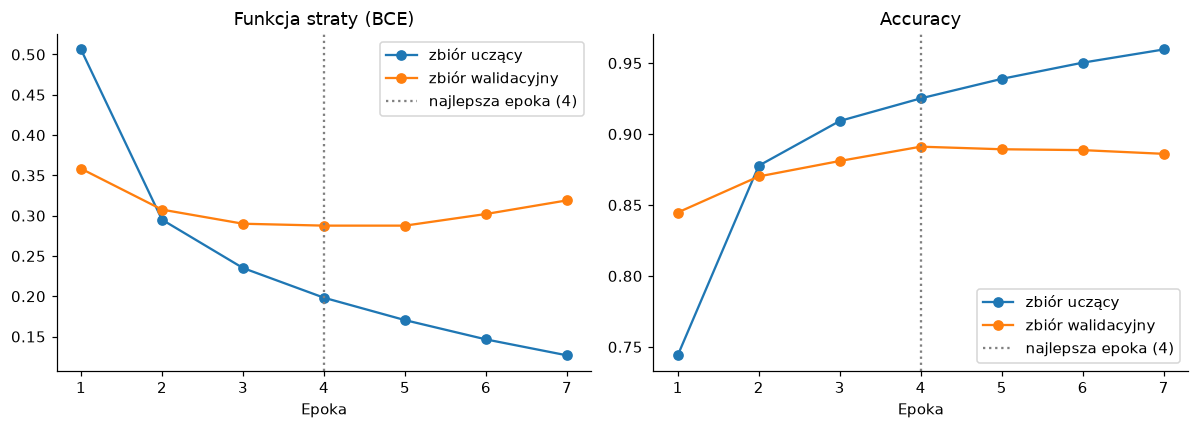

In [18]:
h = pd.DataFrame(history)
best_epoch = int(h.loc[h["val_acc"].idxmax(), "epoch"])

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, metric, title in [(axes[0], "loss", "Funkcja straty (BCE)"), (axes[1], "acc", "Accuracy")]:
    ax.plot(h["epoch"], h[f"train_{metric}"], "o-", label="zbiór uczący")
    ax.plot(h["epoch"], h[f"val_{metric}"], "o-", label="zbiór walidacyjny")
    ax.axvline(best_epoch, color="gray", ls=":", label=f"najlepsza epoka ({best_epoch})")
    ax.set(title=title, xlabel="Epoka")
    ax.legend()
fig.tight_layout()
plt.show()

Strata na zbiorze uczącym stale spada, a na walidacyjnym po kilku epokach zaczyna rosnąć — sieć
zaczyna **przeuczać się** (zapamiętuje zbiór uczący). Dlatego zatrzymujemy trening i bierzemy wagi z najlepszej epoki.

### 7.1 Wynik na zbiorze walidacyjnym

Accuracy (walidacja): 89.11%

              precision    recall  f1-score   support

   negatywna      0.902     0.877     0.889      2470
   pozytywna      0.881     0.906     0.893      2489

    accuracy                          0.891      4959
   macro avg      0.891     0.891     0.891      4959
weighted avg      0.891     0.891     0.891      4959



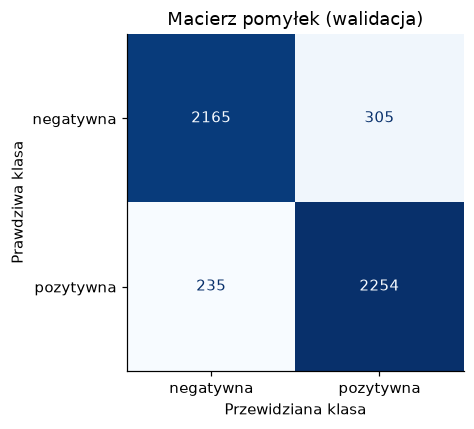

In [19]:
val_probs = predict_proba(model, val_loader, device)
val_preds = (val_probs >= 0.5).astype(int)
acc_nn = accuracy_score(y_val, val_preds)

print(f"Accuracy (walidacja): {acc_nn:.2%}\n")
print(classification_report(y_val, val_preds, target_names=["negatywna", "pozytywna"], digits=3))

fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay(confusion_matrix(y_val, val_preds), display_labels=["negatywna", "pozytywna"]).plot(
    ax=ax, cmap="Blues", colorbar=False, values_format="d"
)
ax.set(title="Macierz pomyłek (walidacja)", xlabel="Przewidziana klasa", ylabel="Prawdziwa klasa")
fig.tight_layout()
plt.show()

Recenzje, przy których model pomylił się najbardziej pewnie:

In [20]:
val_res = val.assign(prob=val_probs, pred=val_preds)
wrong = val_res[val_res["pred"] != val_res["label"]]
wrong = wrong.assign(confidence=(wrong["prob"] - 0.5).abs()).sort_values("confidence", ascending=False)
for _, r in wrong.head(3).iterrows():
    print(f"[prawdziwa: {LABEL_PL[r['sentiment']]}, model: p(pozytywna) = {r['prob']:.2f}]")
    print(textwrap.fill(textwrap.shorten(r["review"], 450), 110), "\n")

[prawdziwa: negatywne, model: p(pozytywna) = 1.00]
Ming The Merciless does a little Bardwork and a movie most foul! 

[prawdziwa: pozytywne, model: p(pozytywna) = 0.00]
This would have worked a lot better if it had been made as "Mitchell in Malta." At least then we would have
been spared the sight of Joe Don Baker running around an otherwise scenic Mediterranean locale clad in that
ridiculous looking cowboy outfit...not to mention acting like an Old West gunslinger. Mitchell being Mitchell,
the film wouldn't have suffered from a lack of gratuitous police brutality either. Oh well. At least the comic
[...] 

[prawdziwa: negatywne, model: p(pozytywna) = 1.00]
Why does the poster & artwork say "Clubbed is one of the best UK indie films I have seen in a very long time.
SCREEN INTERNATIONAL" when it was a quote of the French distributor REPORTED by Screen International (an
influential film trade publication). See www.screendaily.com/ScreenDailyArticle.aspx?intStoryID=39811 which
reads:<br /

In [21]:
config = {"vocab_size": len(vocab), "embed_dim": 64, "hidden_dim": 32, "dropout": 0.3, "max_len": MAX_LEN}
path = save_checkpoint(model, vocab, config, history, name="baseline")
print(f"Zapisano model: {path.relative_to(ROOT)}")

Zapisano model: models/baseline.pt


## 8. Szybki test na własnych zdaniach

Zapowiedź etapu 3 — to samo można uruchomić z terminala: `python -m src.predict "Your review here"`.

In [22]:
own_messages = [
    "This movie was absolutely wonderful, I loved every minute of it.",
    "Terrible acting and a boring plot. Complete waste of time.",
    "The film was not good at all.",
    "I expected it to be bad, but it was surprisingly great.",
    "Not bad.",
    "The visual effects were nice, but the story made no sense.",
]
probs = predict_texts(model, vocab, own_messages, MAX_LEN, device)
pd.DataFrame({"wiadomość": own_messages, "p(pozytywna)": np.round(probs, 3), "wynik": [describe(p) for p in probs]})

,wiadomość,p(pozytywna),wynik
0,"This movie was absolutely wonderful, I loved every minute of it.",1.000,pozytywny (100%)
1,Terrible acting and a boring plot. Complete waste of time.,0.000,negatywny (100%)
2,The film was not good at all.,0.262,negatywny (74%)
3,"I expected it to be bad, but it was surprisingly great.",0.995,pozytywny (100%)
4,Not bad.,0.000,negatywny (100%)
5,"The visual effects were nice, but the story made no sense.",0.013,negatywny (99%)


## Podsumowanie etapu 1

In [23]:
pd.DataFrame(
    {
        "model": ["Losowe zgadywanie", "TF-IDF + regresja logistyczna (bez sieci)", "Sieć bazowa: Embedding + średnia + MLP"],
        "accuracy (walidacja)": [f"{0.5:.1%}", f"{acc_tfidf:.2%}", f"{acc_nn:.2%}"],
    }
)

,model,accuracy (walidacja)
0,Losowe zgadywanie,50.0%
1,TF-IDF + regresja logistyczna (bez sieci),89.13%
2,Sieć bazowa: Embedding + średnia + MLP,89.11%


**Dane**
- 50 000 recenzji, po usunięciu 418 duplikatów zostaje 49 582; klasy są zbalansowane (ok. 50/50).
- Podział 80/10/10 z zachowaniem proporcji klas; zbiór testowy odłożony na etap 3.
- Słownik 20 000 słów pokrywa ok. 97% słów w zbiorze walidacyjnym; recenzje przycięte / dopełnione do 300 słów.

**Wyniki**
- Sieć bazowa osiąga ok. **89%** accuracy na zbiorze walidacyjnym już po 4 epokach (kilka sekund na epokę);
  potem zaczyna się przeuczać, więc wczesne zatrzymanie jest potrzebne.
- To tyle samo co TF-IDF + regresja logistyczna. Oba modele traktują recenzję jak **worek słów** —
  nie wiedzą, w jakiej kolejności słowa występują.

**Ograniczenie, które widać już teraz**
- „Not bad.” model ocenia jako negatywne na 100%: widzi osobno „not” i „bad”, a oba słowa są typowe dla negatywnych recenzji.
- Z analizy danych: słowo „good” występuje w recenzjach negatywnych tak samo często jak „bad” (bo „not good”).

**Dalsze kroki**
- **Etap 2:** sieć rekurencyjna (dwukierunkowy LSTM / GRU), która czyta słowa po kolei i może nauczyć się negacji;
  dobór hiperparametrów, regularyzacja, ewentualnie gotowe wektory słów (GloVe).
- **Etap 3:** końcowa ocena na zbiorze testowym (accuracy, precision, recall, F1, macierz pomyłek), analiza błędów
  (sarkazm, negacje, recenzje mieszane) i test na własnych wiadomościach.